# NumCompute — Streaming Decision Tree Demo

This notebook trains a decision tree on a data stream, using only NumCompute (NumPy + matplotlib):

1. **Load** a CSV with missing values using `io.py`.
2. **Split** it into chunks to simulate streaming.
3. **Train incrementally** with `.partial_fit()`: imputer → scaler → `DecisionTreeClassifier` with buffered retraining, managed by `StreamTrainer`.
4. **Log and visualise** accuracy, error, memory and a model comparison with `visualise.py`.

The dataset (`stream_data.csv`, made by `make_stream_data.py`) has 6,000 rows: four numerical sensor features with 3% missing values and a binary label.

In [81]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Run from a clone without installing the package.
sys.path.insert(0, str(Path.cwd().parent))

from numcompute import (
    DecisionTreeClassifier, Pipeline, SimpleImputer, StandardScaler,
    StreamTrainer, read_csv, read_csv_chunks,
    compare_models, plot_metric_over_time,
    plot_predictions_vs_ground_truth, plot_stream_log,
)

%matplotlib inline
DATA = "stream_data.csv"

## 1. Load the CSV with `io.py`

`read_csv` uses `numpy.genfromtxt`; empty fields become NaN (`missing="fill"`). The header row is skipped.

In [82]:
data = read_csv(DATA, skip_header=1)
X_all, y_all = data[:, :4], data[:, 4].astype(int)

print("shape:", data.shape)
print("missing values per feature:", np.isnan(X_all).sum(axis=0))
print("class counts:", np.bincount(y_all))

shape: (6000, 5)
missing values per feature: [201 184 179 154]
class counts: [2605 3395]


## 2. Simulate a stream

`read_csv_chunks` reads the file **lazily**: only one chunk of 200 rows is in memory at a time. Each chunk is split into features and label.

In [83]:
CHUNK_SIZE = 200

def stream(path=DATA, chunk_size=CHUNK_SIZE):
    for chunk in read_csv_chunks(path, chunk_size=chunk_size, skip_header=1):
        yield chunk[:, :4], chunk[:, 4].astype(int)

chunks = list(stream())
print(f"{len(chunks)} chunks of {CHUNK_SIZE} rows")
print("missing values in the first chunk:", int(np.isnan(chunks[0][0]).sum()))

30 chunks of 200 rows
missing values in the first chunk: 26


## 3. Train incrementally with `partial_fit`

The pipeline imputes missing values (running median), standardises (running mean/variance with Welford's algorithm) and feeds a `DecisionTreeClassifier(max_depth=6, buffer_size=600)`. Each `partial_fit` adds the chunk to the tree's buffer; once 600 samples are buffered, the tree is **retrained on the buffer** and the buffer is cleared. Between retrains, `predict` uses the latest tree.

`StreamTrainer.process_chunk` evaluates **test-then-train**: each chunk is first scored by the model trained on *earlier* chunks, then passed to `pipe.partial_fit`. Every chunk is therefore unseen test data. The predictions for the last chunk are kept for section 6.

In [84]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("impute", SimpleImputer("median")),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=buffer_size,
                                        random_state=0)),
    ])

pipe = make_pipeline(buffer_size=600)
trainer = StreamTrainer(pipe, metrics=("accuracy", "f1", "auc"), window=5)

for i, (X_chunk, y_chunk) in enumerate(chunks):
    if i == len(chunks) - 1:
        last_pred = pipe.predict(X_chunk)         # before training on it
    trainer.process_chunk(X_chunk, y_chunk)       # score, then pipe.partial_fit

print(f"{'chunk':>5} {'scored':>7} {'acc':>6} {'rolling':>8} {'cum acc':>8} "
      f"{'retrained':>10} {'buffered':>9} {'memory KB':>10}")
for e in trainer.history_[:8] + trainer.history_[-3:]:
    print(f"{e['chunk']:>5} {str(e['scored']):>7} {e['chunk_accuracy']:>6.3f} "
          f"{e['rolling_accuracy']:>8.3f} {e['cumulative_accuracy']:>8.3f} "
          f"{str(e['retrained']):>10} {e['n_buffered']:>9} "
          f"{e['memory_bytes'] / 1024:>10.1f}")

chunk  scored    acc  rolling  cum acc  retrained  buffered  memory KB
    0   False    nan      nan      nan      False       200       20.5
    1   False    nan      nan      nan      False       400       40.6
    2   False    nan      nan      nan       True         0       40.5
    3    True  0.905    0.905    0.905      False       200       60.8
    4    True  0.845    0.875    0.875      False       400       80.8
    5    True  0.890    0.880    0.880       True         0       35.7
    6    True  0.855    0.874    0.874      False       200       55.9
    7    True  0.915    0.882    0.882      False       400       75.9
   27    True  0.870    0.881    0.879      False       200       56.5
   28    True  0.845    0.874    0.877      False       400       76.3
   29    True  0.905    0.872    0.879       True         0       35.7


In [85]:
trainer.summary()

{'n_chunks': 30,
 'n_samples': 6000,
 'cumulative_accuracy': 0.8785185185185185,
 'cumulative_f1': 0.8922116332566546,
 'cumulative_auc': 0.8894032461753162,
 'total_fit_time': 0.19187660020543262,
 'n_retrains': 10,
 'final_memory_bytes': 36560}

The first chunks show `NaN`: no tree exists until 600 samples are buffered, so they cannot be scored. Memory grows while the buffer fills and drops after each retrain. The roughly 36 KB that remains is the imputer's bounded median summary plus the trained tree.

## 4. Metrics over time (`visualise.py`)

- **Per-chunk accuracy** is noisy, because each chunk has only 200 samples.
- **Rolling accuracy** (last 5 chunks) shows recent performance.
- **Cumulative accuracy** is the average over everything scored so far.

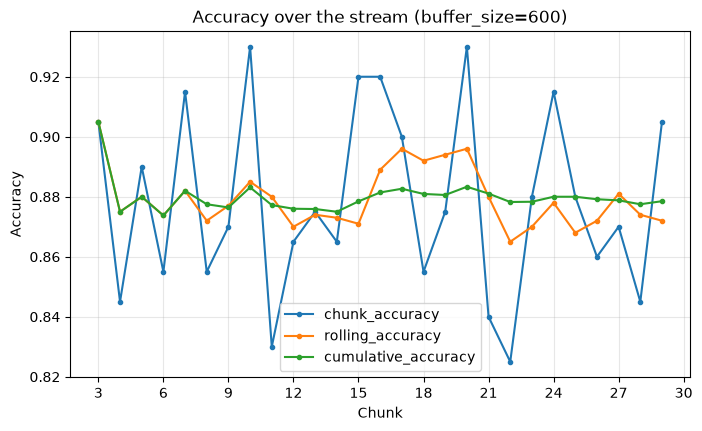

In [86]:
fig = plot_stream_log(
    trainer,
    keys=("chunk_accuracy", "rolling_accuracy", "cumulative_accuracy"),
    title="Accuracy over the stream (buffer_size=600)", ylabel="Accuracy",
)
plt.show()

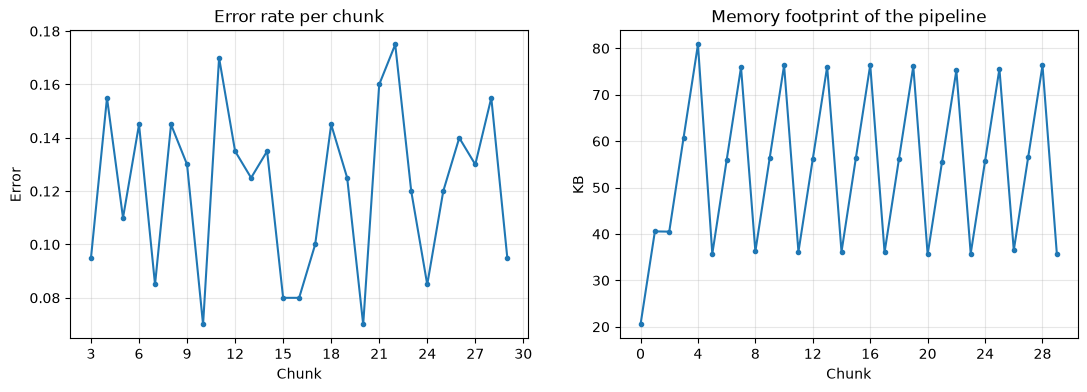

In [87]:
fig, (ax_err, ax_mem) = plt.subplots(1, 2, figsize=(13, 4))
plot_metric_over_time(1 - trainer.get_metric("chunk_accuracy"),
                      title="Error rate per chunk", ylabel="Error", ax=ax_err)
plot_metric_over_time(trainer.get_metric("memory_bytes") / 1024,
                      title="Memory footprint of the pipeline",
                      ylabel="KB", ax=ax_mem)
plt.show()

## 5. Compare models: small vs large buffer

The same stream is processed by two pipelines that differ only in `buffer_size`.

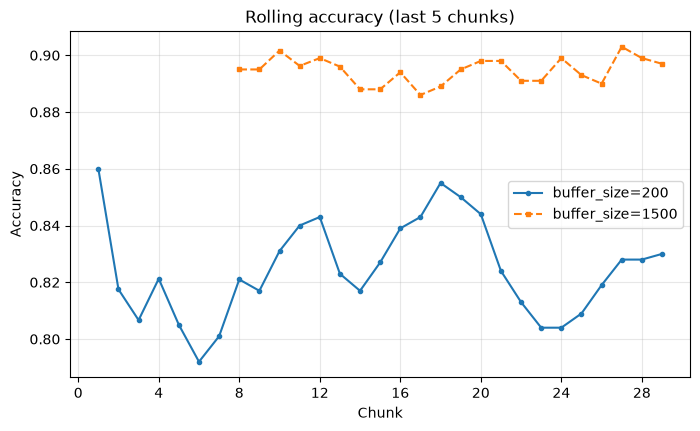

  buffer_size=200: accuracy 0.823, 30 retrains, peak memory 64.3 KB
 buffer_size=1500: accuracy 0.895, 3 retrains, peak memory 116.4 KB


In [88]:
small = StreamTrainer(make_pipeline(buffer_size=200), window=5).run(stream())
large = StreamTrainer(make_pipeline(buffer_size=1500), window=5).run(stream())

compare_models(small.get_metric("rolling_accuracy"),
               large.get_metric("rolling_accuracy"),
               labels=("buffer_size=200", "buffer_size=1500"),
               title="Rolling accuracy (last 5 chunks)", ylabel="Accuracy")
plt.show()

for name, t in (("buffer_size=200", small), ("buffer_size=1500", large)):
    s = t.summary()
    print(f"{name:>17}: accuracy {s['cumulative_accuracy']:.3f}, "
          f"{s['n_retrains']} retrains, peak memory "
          f"{t.get_metric('memory_bytes').max() / 1024:.1f} KB")

## 6. Predictions vs ground truth on the latest chunk

These predictions were made **before** the model trained on this chunk.

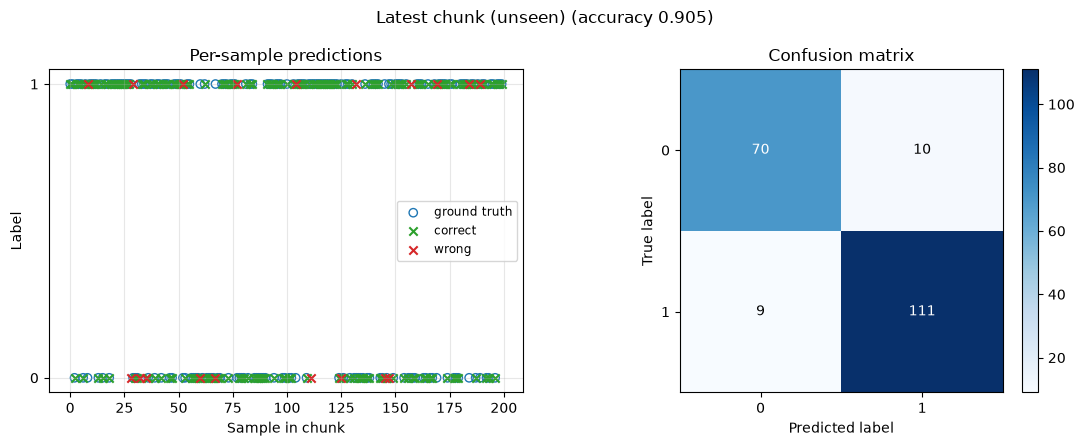

In [89]:
X_last, y_last = chunks[-1]
plot_predictions_vs_ground_truth(y_last, last_pred,
                                 title="Latest chunk (unseen)")
plt.show()

## Summary

- `io.read_csv_chunks` streams the CSV lazily, and `SimpleImputer` handles its missing values on the fly.
- The tree is retrained each time the buffer fills. `predict` uses the latest tree, and memory rises and falls with the buffer.
- A larger buffer gives each retrain more data, but the first tree arrives later and the buffer uses more memory.

Benchmarks (loop vs vectorised, and the effect of `buffer_size`) are run with `python -m numcompute.benchmarking`; results are in the README.